# Hierarchical tracking of convective structures: example

Test of the `src.tracking` algorithms on 3 timesteps of a MesoNH file.

- **Provided by `src/tracking`**: the generic detector (`detect_objects`), the engine (`HierarchicalTrackingEngine`, `TrackingLevel`) and the tracker (`AdvectedIoUTracker`).
- **Defined here (example)**: the parameters, the detection rules of each level (`examples/convective_rules.py`) and the hierarchy of levels.

In [1]:
%matplotlib inline

import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import HTML
from matplotlib.animation import FuncAnimation
from skimage.segmentation import find_boundaries

# `src` must be importable whether the notebook is started from the root or from examples/
repo_root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo_root))

from examples.convective_rules import convective_rules
from src.tracking import AdvectedIoUTracker, HierarchicalTrackingEngine, TrackingLevel, detect_objects

## 1. Data (3 timesteps)

In [4]:
NETCDF_PATH = os.environ.get(
    "NETCDF_PATH",
    "../DATA/sample_caddiwa.nc",
)
N_TIMES = 3

ds = xr.open_dataset(NETCDF_PATH)
if "time" in ds.dims:
    frames = [ds.isel(time=i) for i in range(min(N_TIMES, ds.sizes["time"]))]
else:
    frames = [ds]

time_values = [str(f["time"].values).split("T")[-1].split(".")[0] for f in frames]
timestamps_s = [float(pd.Timestamp(f["time"].values).timestamp()) for f in frames]
print(f"{len(frames)} timesteps: {time_values}")

3 timesteps: ['08:00:00', '08:15:00', '08:30:00']


## 2. Parameters and levels

`convective_rules(PARAMS)` turns the variables and thresholds of `PARAMS` into one detection rule per level (the keys of a rule are listed in `src/tracking/detection.py`). The same generic detector, `detect_objects`, is used for all levels.

In [5]:
PARAMS = {
    # Grid and vertical column
    "dx_km": 1.0,
    "min_alt_km": 0.0,
    "max_alt_km": 20.0,
    # Variables
    "wt_var": "WT",
    "ut_var": "UT",
    "vt_var": "VT",
    "mri_var": "MRI",
    "mrc_var": "MRC",
    "mrs_var": "MRS",
    "mrg_var": "MRG",
    "mrr_var": "MRR",
    "tb_var": "MSG2_IR108",
    # MCS: one seed = one MCS (2D watershed on Tb)
    "tb_env_k": 230.0,        # envelope: Tb <= tb_env_k (maximum extent of an MCS)
    # "tb_seed_h_k": 5.0,   # option of the new algorithm (absent from the old one): minimum depth (K) of a Tb minimum to be a seed; larger = fewer MCS
    "tb_seed_pct": 0.1,      # seeds = percentile (%) of Tb in the envelope (as in the old code)
    "mcs_min_area_km2": 100.0,  # smaller MCS are discarded
    # Convective objects
    "w_thresh": 1.0,
    "hydro_min_gkg": 0.01,
    # Cores
    "core_w_thresh": 4.0,
}

Hierarchy:

- `mcs` is a **root** level;
- `convective_object` is a **child of `mcs`**: its objects are searched within the footprint of an MCS;
- `core` is a **child of `convective_object`**: its cores are searched within a convective object.

Each level has its own tracker (`AdvectedIoUTracker`).

In [6]:
def tracker(prefix, index_key, **kwargs):
    return AdvectedIoUTracker(track_prefix=prefix, index_key=index_key, dx_meters=PARAMS["dx_km"] * 1000.0, **kwargs)


rules = convective_rules(PARAMS)
levels = [
    TrackingLevel("mcs", detect_objects, parent_name=None, params=rules["mcs"],
                  tracker=tracker("mcs", "indices_2d", min_score=0.01, patience=4, max_speed_ms=30.0)),
    TrackingLevel("convective_object", detect_objects, parent_name="mcs", params=rules["convective_object"],
                  tracker=tracker("co", "indices_3d", min_score=0.1, patience=2, pre_filter_pixels=60.0)),
    TrackingLevel("core", detect_objects, parent_name="convective_object", params=rules["core"],
                  tracker=tracker("core", "indices_3d", min_score=0.1, pre_filter_pixels=30.0)),
]
level_names = [lvl.name for lvl in levels]

### Figure 1: hierarchy

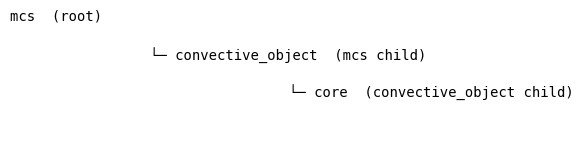

In [7]:
def depth(level):
    parent = {lvl.name: lvl for lvl in levels}.get(level.parent_name)
    return 0 if parent is None else 1 + depth(parent)


fig, ax = plt.subplots(figsize=(6, 1.6))
ax.axis("off")
for i, lvl in enumerate(levels):
    role = "root" if lvl.parent_name is None else f"{lvl.parent_name} child"
    ax.text(0.03 * depth(lvl) * 10, 1 - 0.3 * i, f"{'└─ ' if lvl.parent_name else ''}{lvl.name}  ({role})",
            va="top", family="monospace")
ax.set_ylim(0, 1)
plt.show()

## 3. Detection and tracking

In [8]:
engine = HierarchicalTrackingEngine(levels)
result = engine.run_and_track(datasets=frames, time_values=time_values, timestamps_s=timestamps_s)
results, tracks = result["results_by_time"], result["tracks_by_level"]

pd.DataFrame(
    {name: [len(step["levels"][name]) for step in results] for name in level_names},
    index=pd.Index(time_values, name="time"),
).assign(**{f"tracks {n}": [len(tracks[n])] * len(results) for n in level_names})

,mcs,convective_object,core,tracks mcs,tracks convective_object,tracks core
time,,,,,,
08:00:00,4,89,155,15,254,459
08:15:00,8,85,175,15,254,459
08:30:00,8,94,150,15,254,459


### Figure 2: objects detected at the first timestep

One panel per level, one object per color, black outlines. Convective objects are those within the MCS footprint, cores are those inside the convective objects.

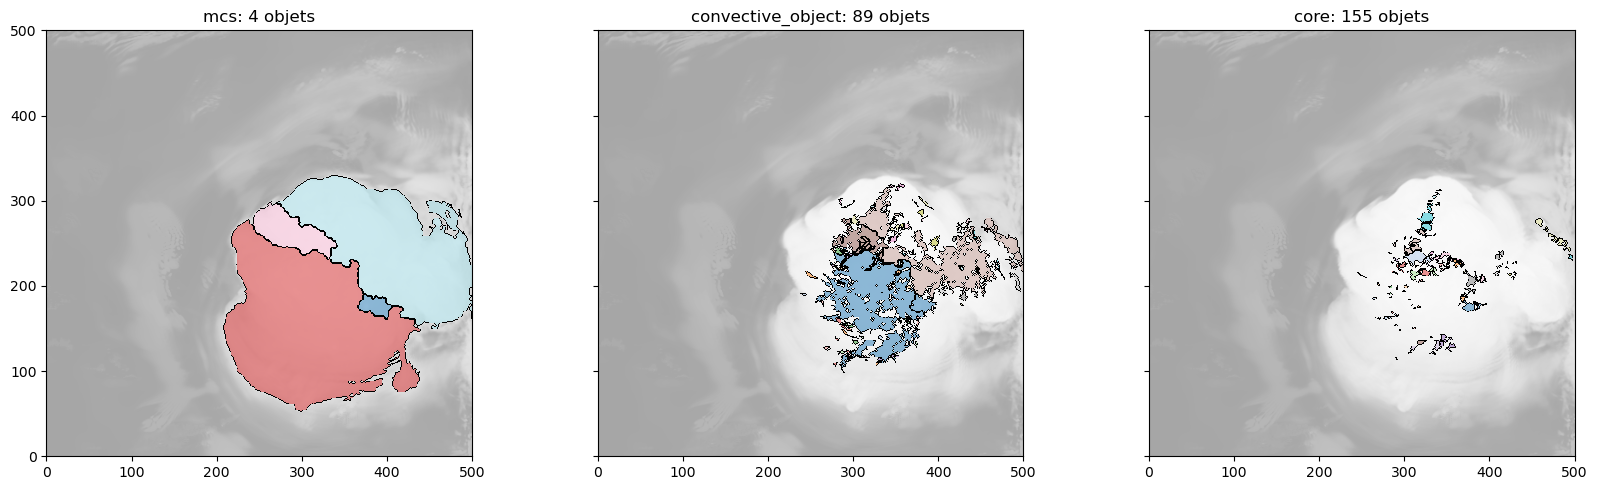

In [19]:
def plot_detection(t):
    tb = np.asarray(frames[t][PARAMS["tb_var"]].values).squeeze()

    fig, axs = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)

    for ax, lvl in zip(axs, levels):
        objs = results[t]["levels"][lvl.name]
        index_key = "indices_2d" if lvl.name == "mcs" else "indices_3d"
        labels = np.zeros(tb.shape, dtype=int)

        for label, obj in enumerate(objs, start=1):
            coords = np.asarray(obj[index_key], dtype=int)
            if coords.size == 0:
                continue

            # Pour les indices 3D (k, j, i), projeter sur (j, i).
            yx = coords[:, -2:]
            labels[yx[:, 0], yx[:, 1]] = label

        ax.imshow(tb, origin="lower", cmap="gray_r", alpha=0.35)

        if objs:
            cmap = plt.get_cmap("tab20", len(objs))
            overlay = np.ma.masked_equal(labels, 0)
            ax.imshow(
                overlay,
                origin="lower",
                cmap=cmap,
                vmin=1,
                vmax=len(objs),
                alpha=COLOR.get("alpha", 0.5),
                interpolation="nearest",
            )

            boundaries = find_boundaries(labels, mode="inner")
            ax.imshow(
                np.ma.masked_equal(boundaries, 0),
                origin="lower",
                cmap="gray_r",
                vmin=0,
                vmax=1,
                interpolation="nearest",
            )

        ax.set_title(f"{lvl.name}: {len(objs)} objets")

    axs[0].set_xlim(VIEW[1].start, VIEW[1].stop)
    axs[0].set_ylim(VIEW[0].start, VIEW[0].stop)
    plt.tight_layout()
    plt.show()


plot_detection(0)

## 4. Temporal tracking (animation)

The color of an object is that of its **track**: the same object keeps the same color from one timestep to the next.

In [18]:
from src.old.fct_core_tracking import find_convective_cores_3d

if "tb_seed_h_k" in PARAMS:
    print("Warning: tb_seed_h_k does not exist in the old code, the MCS will not be identical.")

old = [
    find_convective_cores_3d(
        f,
        wt_var=PARAMS["wt_var"], ut_var=PARAMS["ut_var"], vt_var=PARAMS["vt_var"],
        mri_var=PARAMS["mri_var"], mrc_var=PARAMS["mrc_var"], mrs_var=PARAMS["mrs_var"],
        mrg_var=PARAMS["mrg_var"], mrr_var=PARAMS["mrr_var"], tb_var=PARAMS["tb_var"],
        w_thresh=PARAMS["w_thresh"],
        min_alt_km=PARAMS["min_alt_km"], max_alt_km=PARAMS["max_alt_km"],
        tb_seed_pct=PARAMS.get("tb_seed_pct"), tb_seed_k=PARAMS.get("tb_seed_k", 190.0),
        tb_env_k=PARAMS["tb_env_k"], hydro_min_gkg=PARAMS["hydro_min_gkg"],
        mcs_min_area_km2=PARAMS["mcs_min_area_km2"],
    )[0]
    for f in frames
]

# New detectors, same root levels as the old code
flat_levels = [
    TrackingLevel("mcs", detect_objects, parent_name=None, params=rules["mcs"]),
    TrackingLevel("convective_object", detect_objects, parent_name=None, params=rules["convective_object"]),
    TrackingLevel("core", detect_objects, parent_name="convective_object", params=rules["core"]),
]
new_flat = HierarchicalTrackingEngine(flat_levels).run(frames, time_values)


def footprints(objs, key):
    return {frozenset(map(tuple, o[key])) for o in objs}


rows = []
for t in range(len(frames)):
    for name, old_key, idx_key in (("mcs", "mcs", "indices_2d"),
                                   ("convective_object", "conv_objects", "indices_3d"),
                                   ("core", "cores", "indices_3d")):
        o, n = old[t][old_key], new_flat[t]["levels"][name]
        rows.append({
            "time": time_values[t], "level": name,
            "old": len(o), "new": len(n),
            "identical": footprints(o, idx_key) == footprints(n, idx_key),
            "hierarchy": len(results[t]["levels"][name]),
        })
comparison = pd.DataFrame(rows).set_index(["time", "level"])
comparison

KeyError: "No variable named 'level_w'. Variables on the dataset include ['time', 'longitude', 'latitude', 'ni_u', 'nj_v', ..., 'TEMP', 'MRC', 'dpr_35refl', 'cpr_94refl', 'PRES']"

In [52]:
ds.close()